In [ ]:
from google.colab import files

uploaded = files.upload()

Saving DatasetLR.csv to DatasetLR.csv


In [ ]:
# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler

# Load dataset
# If your file name is different, change it here
df = pd.read_csv("DatasetLR.csv")

# Display first 10 records
print("First 10 records:")
display(df.head(10))

# Number of rows and columns
print("\nNumber of rows and columns:")
print(df.shape)

# Column names
print("\nColumn names:")
print(df.columns.tolist())

# Missing values
print("\nMissing values:")
print(df.isnull().sum())

# Duplicate records
print("\nNumber of duplicate records:")
print(df.duplicated().sum())

# Display dataset information
print("\nDataset Information:")
df.info()

First 10 records:


,Study_Hours,Sleep_Hours,Attendance,Previous_Score,Assignments_Completed,Exam_Score
0,1.5,5.7,93,88,92,60.9
1,6.5,6.6,72,69,79,82.1
2,4.1,7.9,92,50,74,71.4
3,6.1,6.8,98,90,75,84.9
4,7.8,7.3,88,52,99,89.0
5,4.8,7.7,79,66,64,72.0
6,4.5,8.0,90,72,96,72.4
7,1.5,7.8,91,86,94,61.4
8,2.9,5.5,90,83,69,64.6
9,4.5,6.8,74,74,74,71.9



Number of rows and columns:
(100, 6)

Column names:
['Study_Hours', 'Sleep_Hours', 'Attendance', 'Previous_Score', 'Assignments_Completed', 'Exam_Score']

Missing values:
Study_Hours              0
Sleep_Hours              0
Attendance               0
Previous_Score           0
Assignments_Completed    0
Exam_Score               0
dtype: int64

Number of duplicate records:
0

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 6 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Study_Hours            100 non-null    float64
 1   Sleep_Hours            100 non-null    float64
 2   Attendance             100 non-null    int64  
 3   Previous_Score         100 non-null    int64  
 4   Assignments_Completed  100 non-null    int64  
 5   Exam_Score             100 non-null    float64
dtypes: float64(3), int64(3)
memory usage: 4.8 KB


Correlation Matrix:


,Study_Hours,Sleep_Hours,Attendance,Previous_Score,Assignments_Completed,Exam_Score
Study_Hours,1.000000,0.155749,0.080967,-0.147930,-0.037457,0.958313
Sleep_Hours,0.155749,1.000000,-0.142734,-0.080044,0.143731,0.264658
Attendance,0.080967,-0.142734,1.000000,-0.110322,-0.025918,0.115301
Previous_Score,-0.147930,-0.080044,-0.110322,1.000000,0.003584,0.025894
Assignments_Completed,-0.037457,0.143731,-0.025918,0.003584,1.000000,0.074850
Exam_Score,0.958313,0.264658,0.115301,0.025894,0.074850,1.000000


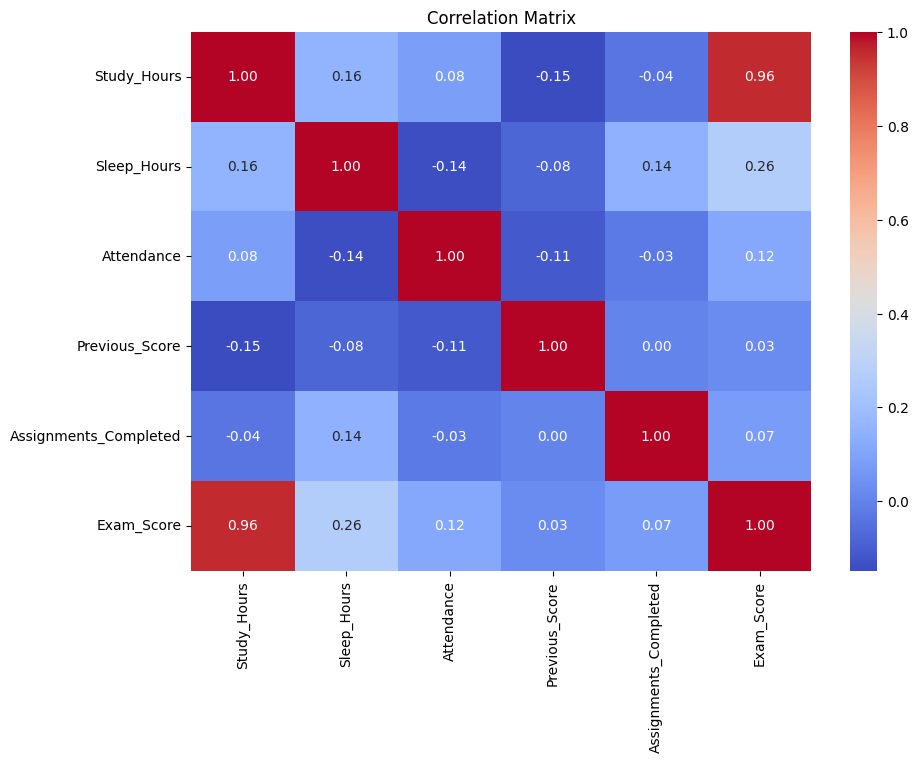

Strongest predictor of Exam_Score: Study_Hours
Correlation: 0.9583129078269176


In [ ]:
# Select numerical columns
numeric_df = df.select_dtypes(include=np.number)

# Calculate correlation matrix
correlation_matrix = numeric_df.corr()

print("Correlation Matrix:")
display(correlation_matrix)

# Plot correlation heatmap
plt.figure(figsize=(10, 7))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix")
plt.show()

# Find strongest predictor of Exam_Score
correlations = correlation_matrix["Exam_Score"].drop("Exam_Score")

strongest_predictor = correlations.abs().idxmax()

print("Strongest predictor of Exam_Score:", strongest_predictor)
print("Correlation:", correlations[strongest_predictor])

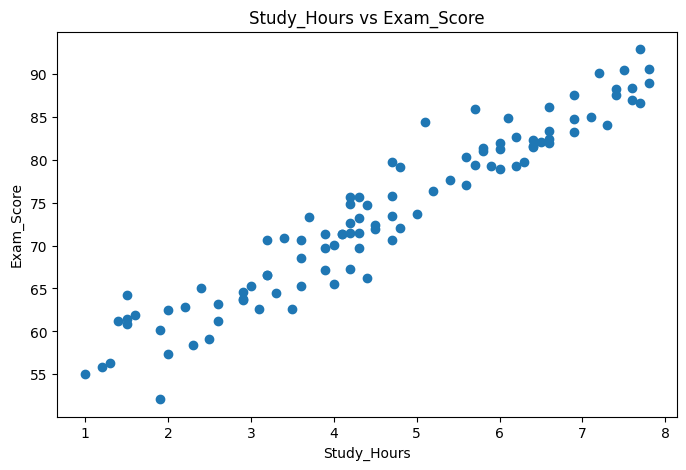

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df[strongest_predictor],
    df["Exam_Score"]
)

plt.xlabel(strongest_predictor)
plt.ylabel("Exam_Score")
plt.title(f"{strongest_predictor} vs Exam_Score")

plt.show()

In [ ]:
# Independent variables
features = [
    "Study_Hours",
    "Sleep_Hours",
    "Attendance",
    "Previous_Score",
    "Assignments_Completed"
]

# Dependent variable
target = "Exam_Score"

X = df[features]
y = df[target]

# Split into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

# Create Linear Regression model
model = LinearRegression()

# Train model
model.fit(X_train, y_train)

# Predictions
y_pred = model.predict(X_test)

print("\nModel trained successfully.")

Training data: (80, 5)
Testing data: (20, 5)

Model trained successfully.


In [ ]:
# Display intercept
print("Intercept:", model.intercept_)

# Display coefficients
print("\nCoefficients:")

for feature, coefficient in zip(features, model.coef_):
    print(f"{feature}: {coefficient}")

Intercept: 16.174179199719937

Coefficients:
Study_Hours: 5.070140870721533
Sleep_Hours: 1.3790053433452873
Attendance: 0.08238619792375568
Previous_Score: 0.15161054658767226
Assignments_Completed: 0.08536743324134649


In [ ]:
print("\nMultiple Linear Regression Equation:")

equation = f"Exam_Score = {model.intercept_:.4f}"

for feature, coefficient in zip(features, model.coef_):
    sign = "+" if coefficient >= 0 else "-"
    equation += f" {sign} {abs(coefficient):.4f}({feature})"

print(equation)


Multiple Linear Regression Equation:
Exam_Score = 16.1742 + 5.0701(Study_Hours) + 1.3790(Sleep_Hours) + 0.0824(Attendance) + 0.1516(Previous_Score) + 0.0854(Assignments_Completed)


In [ ]:
# Calculate evaluation metrics

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

# Number of observations
n = len(y_test)

# Number of predictors
p = X_test.shape[1]

# Adjusted R²
adjusted_r2 = 1 - ((1 - r2) * (n - 1) / (n - p - 1))

print("Model Evaluation")
print("-------------------------")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R²:", r2)
print("Adjusted R²:", adjusted_r2)

Model Evaluation
-------------------------
MAE: 0.8310910050914654
MSE: 1.0113326354943053
RMSE: 1.0056503544941977
R²: 0.9883776611272511
Adjusted R²: 0.9842268258155551


In [ ]:
# Function to evaluate a model
def evaluate_model(features_list):

    X_model = df[features_list]
    y_model = df["Exam_Score"]

    X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(
        X_model,
        y_model,
        test_size=0.20,
        random_state=42
    )

    model_m = LinearRegression()
    model_m.fit(X_train_m, y_train_m)

    predictions = model_m.predict(X_test_m)

    mae = mean_absolute_error(y_test_m, predictions)
    mse = mean_squared_error(y_test_m, predictions)
    rmse = np.sqrt(mse)

    r2 = r2_score(y_test_m, predictions)

    n = len(y_test_m)
    p = X_test_m.shape[1]

    adjusted_r2 = 1 - ((1 - r2) * (n - 1) / (n - p - 1))

    return mae, mse, rmse, r2, adjusted_r2


# Model 1
model1_features = [
    "Study_Hours"
]

# Model 2
model2_features = [
    "Study_Hours",
    "Sleep_Hours"
]

# Model 3
model3_features = [
    "Study_Hours",
    "Sleep_Hours",
    "Attendance",
    "Previous_Score",
    "Assignments_Completed"
]


# Evaluate all models
result1 = evaluate_model(model1_features)
result2 = evaluate_model(model2_features)
result3 = evaluate_model(model3_features)


# Create comparison table
comparison = pd.DataFrame({
    "Model": [
        "Model 1",
        "Model 2",
        "Model 3"
    ],

    "Features": [
        "Study_Hours",
        "Study_Hours + Sleep_Hours",
        "All 5 Features"
    ],

    "MAE": [
        result1[0],
        result2[0],
        result3[0]
    ],

    "MSE": [
        result1[1],
        result2[1],
        result3[1]
    ],

    "RMSE": [
        result1[2],
        result2[2],
        result3[2]
    ],

    "R²": [
        result1[3],
        result2[3],
        result3[3]
    ],

    "Adjusted R²": [
        result1[4],
        result2[4],
        result3[4]
    ]
})

display(comparison)
best_model_index = comparison["R²"].idxmax()

print(
    "Model with highest R²:",
    comparison.loc[best_model_index, "Model"]
)

,Model,Features,MAE,MSE,RMSE,R²,Adjusted R²
0,Model 1,Study_Hours,1.956783,5.231123,2.287165,0.939883,0.936544
1,Model 2,Study_Hours + Sleep_Hours,2.010808,5.627060,2.372142,0.935333,0.927725
2,Model 3,All 5 Features,0.831091,1.011333,1.005650,0.988378,0.984227


Model with highest R²: Model 3


In [ ]:
best_model_index = comparison["R²"].idxmax()

print(
    "Model with highest R²:",
    comparison.loc[best_model_index, "Model"]
)

Model with highest R²: Model 3


In [ ]:
# Use all five features
X = df[features].values
y = df["Exam_Score"].values

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Standardize input features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Standardization completed.")

Standardization completed.


In [ ]:
def gradient_descent(X, y, learning_rate=0.01, epochs=1000):

    # Number of samples and features
    m, n = X.shape

    # Initialize weights and bias
    weights = np.zeros(n)
    bias = 0

    # Store cost values
    cost_history = []

    for epoch in range(epochs):

        # Prediction
        y_pred = np.dot(X, weights) + bias

        # Error
        error = y_pred - y

        # Calculate gradients
        dw = (1 / m) * np.dot(X.T, error)
        db = (1 / m) * np.sum(error)

        # Update weights
        weights = weights - learning_rate * dw

        # Update bias
        bias = bias - learning_rate * db

        # Calculate cost
        cost = (1 / (2 * m)) * np.sum(error ** 2)

        cost_history.append(cost)

    return weights, bias, cost_history

In [ ]:
# Train Gradient Descent
weights, bias, cost_history = gradient_descent(
    X_train_scaled,
    y_train,
    learning_rate=0.01,
    epochs=1000
)

print("Final Weights:")
print(weights)

print("\nFinal Bias:")
print(bias)

Final Weights:
[9.37997145 1.26425441 0.75914813 1.7300147  0.96143632]

Final Bias:
73.81931299058803


In [ ]:
# Predictions
gd_predictions = np.dot(X_test_scaled, weights) + bias

# Metrics
gd_mae = mean_absolute_error(y_test, gd_predictions)

gd_mse = mean_squared_error(y_test, gd_predictions)

gd_rmse = np.sqrt(gd_mse)

gd_r2 = r2_score(y_test, gd_predictions)

n = len(y_test)
p = X_test_scaled.shape[1]

gd_adjusted_r2 = 1 - (
    (1 - gd_r2) * (n - 1) / (n - p - 1)
)

print("Gradient Descent Evaluation")
print("-----------------------------")
print("MAE:", gd_mae)
print("MSE:", gd_mse)
print("RMSE:", gd_rmse)
print("R²:", gd_r2)
print("Adjusted R²:", gd_adjusted_r2)

Gradient Descent Evaluation
-----------------------------
MAE: 0.8306703505429741
MSE: 1.012742839309691
RMSE: 1.0063512504636196
R²: 0.9883614549196723
Adjusted R²: 0.9842048316766981


In [ ]:
learning_rates = [0.001, 0.01, 0.1]

results_lr = {}

for lr in learning_rates:

    weights_lr, bias_lr, cost_history_lr = gradient_descent(
        X_train_scaled,
        y_train,
        learning_rate=lr,
        epochs=1000
    )

    predictions_lr = (
        np.dot(X_test_scaled, weights_lr) + bias_lr
    )

    mae = mean_absolute_error(y_test, predictions_lr)

    mse = mean_squared_error(y_test, predictions_lr)

    rmse = np.sqrt(mse)

    r2 = r2_score(y_test, predictions_lr)

    n = len(y_test)
    p = X_test_scaled.shape[1]

    adjusted_r2 = 1 - (
        (1 - r2) * (n - 1) / (n - p - 1)
    )

    results_lr[lr] = {
        "weights": weights_lr,
        "bias": bias_lr,
        "cost": cost_history_lr,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R²": r2,
        "Adjusted R²": adjusted_r2
    }

print("Learning rate experiment completed.")

Learning rate experiment completed.


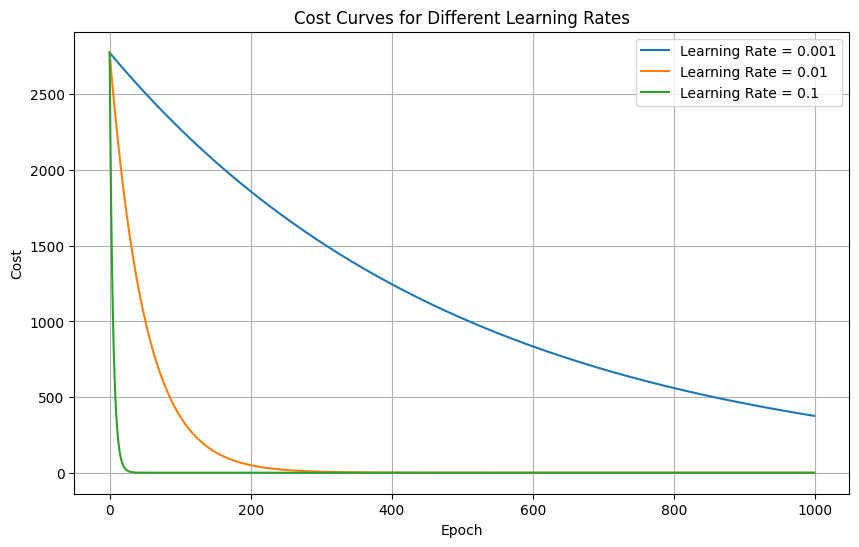

In [ ]:
plt.figure(figsize=(10, 6))

for lr in learning_rates:

    plt.plot(
        results_lr[lr]["cost"],
        label=f"Learning Rate = {lr}"
    )

plt.xlabel("Epoch")
plt.ylabel("Cost")
plt.title("Cost Curves for Different Learning Rates")
plt.legend()
plt.grid()

plt.show()

In [ ]:
lr_comparison = pd.DataFrame({

    "Learning Rate": learning_rates,

    "MAE": [
        results_lr[lr]["MAE"]
        for lr in learning_rates
    ],

    "MSE": [
        results_lr[lr]["MSE"]
        for lr in learning_rates
    ],

    "RMSE": [
        results_lr[lr]["RMSE"]
        for lr in learning_rates
    ],

    "R²": [
        results_lr[lr]["R²"]
        for lr in learning_rates
    ],

    "Adjusted R²": [
        results_lr[lr]["Adjusted R²"]
        for lr in learning_rates
    ]
})

display(lr_comparison)

,Learning Rate,MAE,MSE,RMSE,R²,Adjusted R²
0,0.001,27.528864,770.567512,27.759098,-7.855441,-11.018099
1,0.010,0.830670,1.012743,1.006351,0.988361,0.984205
2,0.100,0.831091,1.011333,1.005650,0.988378,0.984227


In [ ]:
# Scikit-learn results
sklearn_results = {
    "Model": "Scikit-learn",
    "MAE": mae,
    "MSE": mse,
    "RMSE": rmse,
    "R²": r2,
    "Adjusted R²": adjusted_r2
}

# Gradient Descent results
gradient_results = {
    "Model": "Gradient Descent",
    "MAE": gd_mae,
    "MSE": gd_mse,
    "RMSE": gd_rmse,
    "R²": gd_r2,
    "Adjusted R²": gd_adjusted_r2
}

comparison_sklearn_gd = pd.DataFrame([
    sklearn_results,
    gradient_results
])

display(comparison_sklearn_gd)

,Model,MAE,MSE,RMSE,R²,Adjusted R²
0,Scikit-learn,0.831091,1.011333,1.005650,0.988378,0.984227
1,Gradient Descent,0.830670,1.012743,1.006351,0.988361,0.984205


In [ ]:
# Create a new student

new_student = pd.DataFrame({
    "Study_Hours": [6],
    "Sleep_Hours": [7],
    "Attendance": [90],
    "Previous_Score": [75],
    "Assignments_Completed": [9]
})

# Predict Exam Score
new_prediction = model.predict(new_student)

print("New Student Details:")
display(new_student)

print(
    "Predicted Exam Score:",
    new_prediction[0]
)

New Student Details:


,Study_Hours,Sleep_Hours,Attendance,Previous_Score,Assignments_Completed
0,6,7,90,75,9


Predicted Exam Score: 75.8019175338517
